# 08 · Native track: comparing the three controllers

> **In short:** run deterministic, individual-risk and joint-risk NMPC on the same scenario and seed, then compare paths, clearance, goal error, solve time and supervisor activity.
>
> **Runtime:** about 1–2 minutes (shorter with FAST) · **Read alongside:** [Native simulation](../2.Code/docs/guides/native-simulation.md) · [Safety supervisor](../2.Code/docs/concepts/safety-fallback.md)

**You will:**

- run three paired episodes
- plot paths and clearance
- read the solve-time budget and the supervisor counters

In [1]:
from nbsetup import *

In [2]:
from quadrotor_mpc.application.native.headless import run_headless_episode
from quadrotor_mpc.application.native.telemetry import load_native_recording

SCENARIO = CONFIG / "mujoco_native_ccmpc.yaml"


def run(mode, seed=1001, duration=None):
    episode = run_headless_episode(SCENARIO, mode=mode, seed=seed, duration_s=duration, base_dir=OUTPUT)
    print(f"{mode:13s} {episode.result['termination_reason']}, collision={episode.result['collided']}, "
          f"recording: {episode.recording.name}")
    return load_native_recording(episode.recording)


def column(recording, name):
    return np.array([float(row[name]) if row[name] not in ("", None) else np.nan for row in recording["rows"]])

In [3]:
duration = 3.0 if FAST else None  # None = scenario duration (10 s)
modes = ("deterministic", "individual", "joint_uniform")
runs = {mode: run(mode, duration=duration) for mode in modes}

deterministic duration_reached, collision=False, recording: 20261011T150003Z_ccmpc-mujoco-native-estimated-dynamic-deterministic


individual    duration_reached, collision=False, recording: 20261011T150020Z_ccmpc-mujoco-native-estimated-dynamic-individual


joint_uniform duration_reached, collision=False, recording: 20261011T150046Z_ccmpc-mujoco-native-estimated-dynamic-joint_uniform


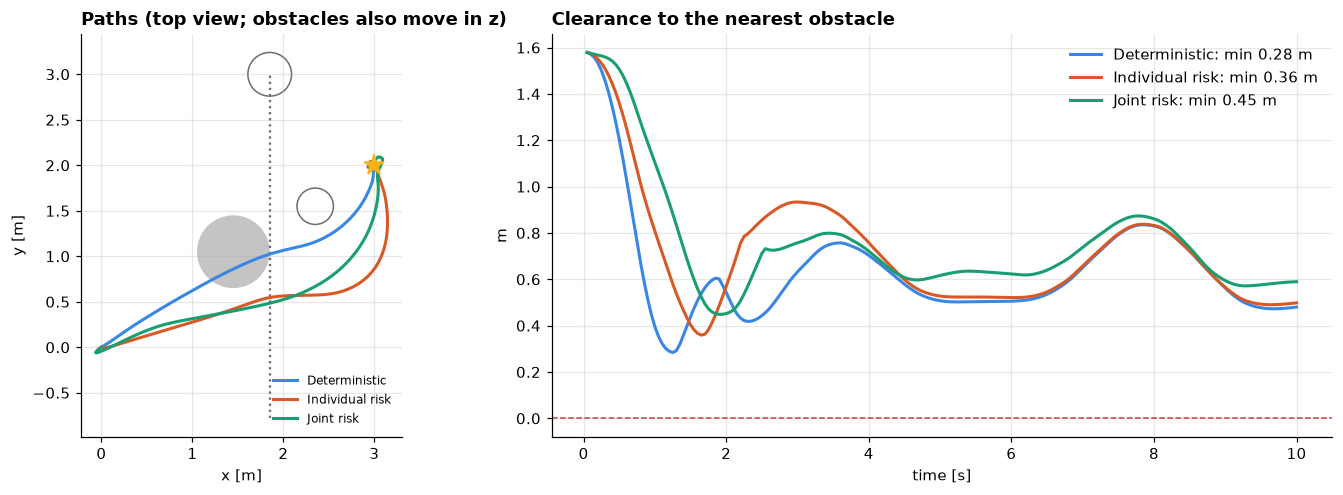

In [4]:
from matplotlib.patches import Circle

reference = runs["joint_uniform"]
fig, (ax_top, ax_clear) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1, 1.3]})
paths = reference["obstacle_predictions"][:, :, 0, :]
for j, spec in enumerate(reference["scenario"]["obstacles"]):
    if spec["type"] == "static":
        center = spec.get("position") or [spec["x"], spec["y"], spec["z"]]
        ax_top.add_patch(Circle(center[:2], spec["radius"], fc=NEUTRAL, alpha=0.4))
    else:
        ax_top.plot(paths[:, j, 0], paths[:, j, 1], ls=":", color=NEUTRAL)
        ax_top.add_patch(Circle(paths[-1, j, :2], spec["radius"], fc="none", ec=NEUTRAL))
for mode, rec in runs.items():
    states = rec["states"]
    ax_top.plot(states[:, 0], states[:, 1], color=CONTROLLER_COLORS[mode], lw=2, label=CONTROLLER_LABELS[mode])
    clearance = column(rec, "min_clearance_m")
    ax_clear.plot(column(rec, "time_s"), clearance, color=CONTROLLER_COLORS[mode], lw=2,
                  label=f"{CONTROLLER_LABELS[mode]}: min {np.nanmin(clearance):.2f} m")
goal = reference["scenario"]["goal"]["position"]
ax_top.plot(goal["x"], goal["y"], "*", ms=14, color="#fab219")
ax_top.set(title="Paths (top view; obstacles also move in z)", xlabel="x [m]", ylabel="y [m]", aspect="equal")
ax_top.legend(loc="lower right", fontsize=8)
ax_clear.axhline(0, color=CRITICAL, ls="--", lw=1)
ax_clear.set(title="Clearance to the nearest obstacle", xlabel="time [s]", ylabel="m")
ax_clear.legend()
plt.tight_layout()
plt.show()

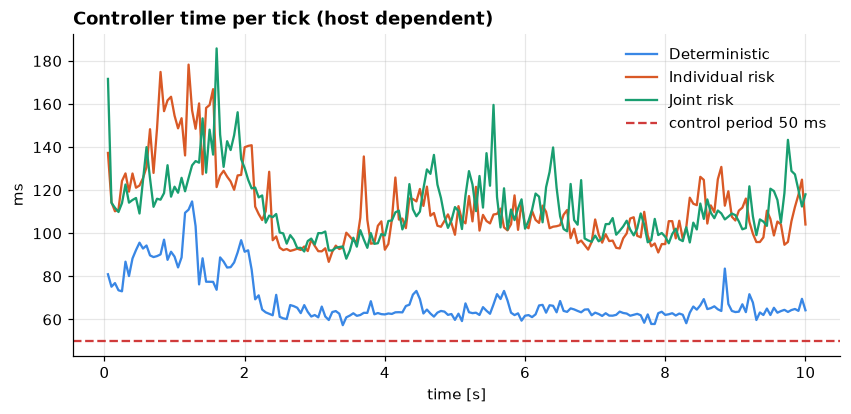

controller     min clear final err  p99 ms fallback max slack
Deterministic      0.284     0.052   109.5        0    28.3mm
Individual risk     0.359     0.040   167.0        0     4.6mm
Joint risk         0.449     0.078   159.7        0     7.1mm


In [5]:
period_ms = 1000 * reference["scenario"]["simulation"]["mpc_timestep_s"]
fig, ax = plt.subplots(figsize=(9, 3.8))
for mode, rec in runs.items():
    ax.plot(column(rec, "time_s"), column(rec, "solver_time_ms"), color=CONTROLLER_COLORS[mode], label=CONTROLLER_LABELS[mode])
ax.axhline(period_ms, color=CRITICAL, ls="--", label=f"control period {period_ms:.0f} ms")
ax.set(title="Controller time per tick (host dependent)", xlabel="time [s]", ylabel="ms")
ax.legend()
plt.show()

print(f"{'controller':14s} {'min clear':>9s} {'final err':>9s} {'p99 ms':>7s} {'fallback':>8s} {'max slack':>9s}")
for mode, rec in runs.items():
    solve = column(rec, "solver_time_ms")
    fallback = sum(str(row["fallback_active"]).lower() in ("true", "1") for row in rec["rows"])
    print(f"{CONTROLLER_LABELS[mode]:14s} {np.nanmin(column(rec, 'min_clearance_m')):9.3f} "
          f"{column(rec, 'goal_distance_m')[-1]:9.3f} {np.nanpercentile(solve, 99):7.1f} {fallback:8d} "
          f"{1000 * np.nanmax(column(rec, 'maximum_slack_m')):7.1f}mm")

## Takeaways

- Clearance increases from deterministic to individual to joint risk; all three reach the goal here.
- The chance controllers take longer than the 50 ms period on typical hardware. The shipped scenario
  records deadline misses but still applies valid late solutions (`reject_on_deadline_miss: false`).
- A single seed is an illustration. Statistical statements come from paired Monte Carlo campaigns,
  covered in the last notebook.

---

**Previous:** [07_native_uncertainty_and_risk.ipynb](07_native_uncertainty_and_risk.ipynb) · **Next:** [09_monte_carlo_statistics.ipynb](09_monte_carlo_statistics.ipynb)